In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


In [2]:
data = pd.read_csv('https://raw.githubusercontent.com/dphi-official/Linear_Regression_Introduction/master/Salary_Data.csv')
data.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


Let's check if there is a relationship between the variables

In [3]:
np.corrcoef(data['YearsExperience'],data['Salary'])

array([[1.        , 0.97824162],
       [0.97824162, 1.        ]])

There is a positive relationship between years of Experience and Salary meaning that as your years of Experience increases there is a subsequent increase in salary

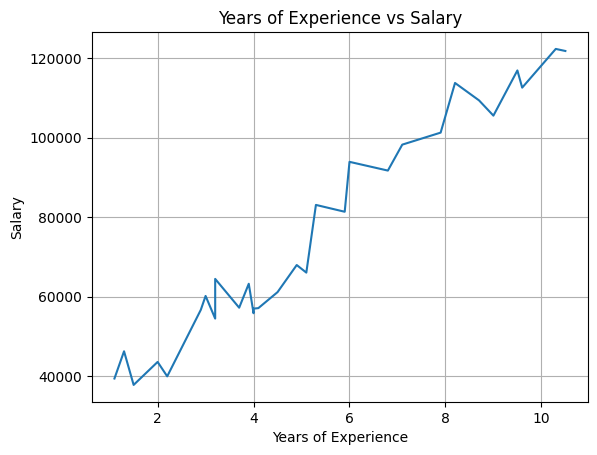

In [28]:
#plotting a bar plot
plt.plot(data['YearsExperience'],data['Salary'])
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Years of Experience vs Salary')
plt.grid(True)
plt.show()

In [11]:
# Let's describe our data
data.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


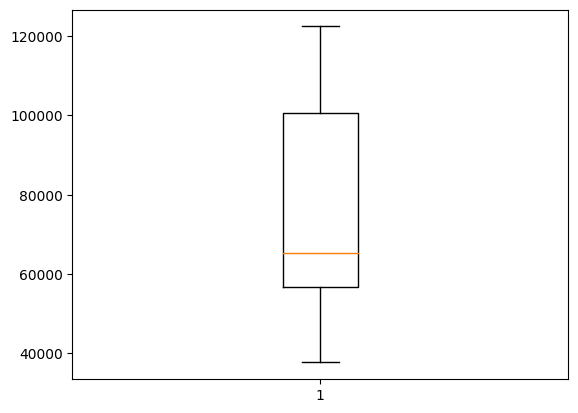

In [12]:
plt.boxplot(data['Salary'])
plt.show()

In [13]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 608.0 bytes


In [14]:
data.columns

Index(['YearsExperience', 'Salary'], dtype='object')

In [19]:
# Let's split the data into Dependent and independent variable
x = data[['YearsExperience']]
y = data['Salary']

In [17]:
# Split the data into test set and training set
from sklearn import model_selection
x_test,x_train,y_test,y_train = model_selection.train_test_split(x,y,test_size = 0.3)

In [20]:
# Now let's fit a simple linear regression model
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train,y_train)

ValueError: Expected 2D array, got 1D array instead:
array=[ 2.2  9.6  3.   4.   1.3  4.1  9.5 10.5  5.1].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

In [21]:
# Let's split the data into Dependent and independent variable
x = data[['YearsExperience']] # x is already a DataFrame
y = data['Salary']

# Split the data into test set and training set
from sklearn import model_selection
x_test,x_train,y_test,y_train = model_selection.train_test_split(x,y,test_size = 0.3)

# Now let's fit a simple linear regression model
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train,y_train) # x_train is a DataFrame

LinearRegression()

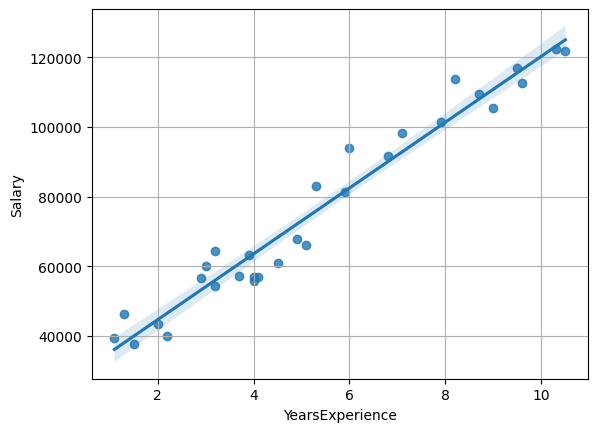

In [22]:
import seaborn as sns
sns.regplot(x = data['YearsExperience'],y = data['Salary'])
plt.grid(True)
plt.show()

Now obtaining the coefficients and the slope

In [23]:
print(model.coef_)
print(model.intercept_)

[8504.0213106]
27002.75023974428


Now the regression equation is : y = 8504.02131x + 27002.75

It's now evident that an increase in x leads to a 27002.75 increase in y

In [24]:
# Let's predict the observations in the x test
model.predict(x_test)

array([ 60168.43335109,  94184.5185935 ,  96735.72498668,  87381.30154502,
       114594.16973895, 100987.73564198,  51664.41204049,  68672.45466169,
        78026.87810336,  38057.97794353,  84830.09515184, 116294.97400107,
        61018.83548215, 108641.35482152,  72074.06318593,  61869.23761321,
        52514.81417155,  44010.79286095,  61018.83548215, 103538.94203516,
       107790.95269046])

In [26]:
# Now let's evaluate our Linear Regression using mean absolute error
from sklearn.metrics import mean_absolute_error
print("The mean squared error in the test data is ",mean_absolute_error(y_test,model.predict(x_test)))

The mean squared error in the test data is  6907.467052287094


In [27]:
print("The mean absolute error in the train data is ", mean_absolute_error(y_train,model.predict(x_train)))

The mean absolute error in the train data is  3918.025217545728
